In [1]:
import pandas as pd
import geopandas as gpd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point

## 1. Global Earthquakes

In [2]:
# 1.读取地震数据
df = pd.read_csv("Data/usgs_earthquakes.csv")

print("===== 数据集基本信息 =====")
df.info()

print("\n===== 数据样例 =====")
print(df.head())

print("\n===== 震级统计描述 =====")
print(df["mag"].describe())

===== 数据集基本信息 =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120108 entries, 0 to 120107
Data columns (total 15 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   time       120108 non-null  object 
 1   latitude   120108 non-null  float64
 2   longitude  120108 non-null  float64
 3   depth      120107 non-null  float64
 4   mag        120065 non-null  float64
 5   magType    120065 non-null  object 
 6   nst        59688 non-null   float64
 7   gap        94935 non-null   float64
 8   dmin       85682 non-null   float64
 9   rms        119716 non-null  float64
 10  net        120108 non-null  object 
 11  id         120108 non-null  object 
 12  updated    120108 non-null  object 
 13  place      120108 non-null  object 
 14  type       120108 non-null  object 
dtypes: float64(8), object(7)
memory usage: 13.7+ MB

===== 数据样例 =====
                      time   latitude  longitude  depth   mag magType  nst  \
0  2014-01-31 23:53:37.

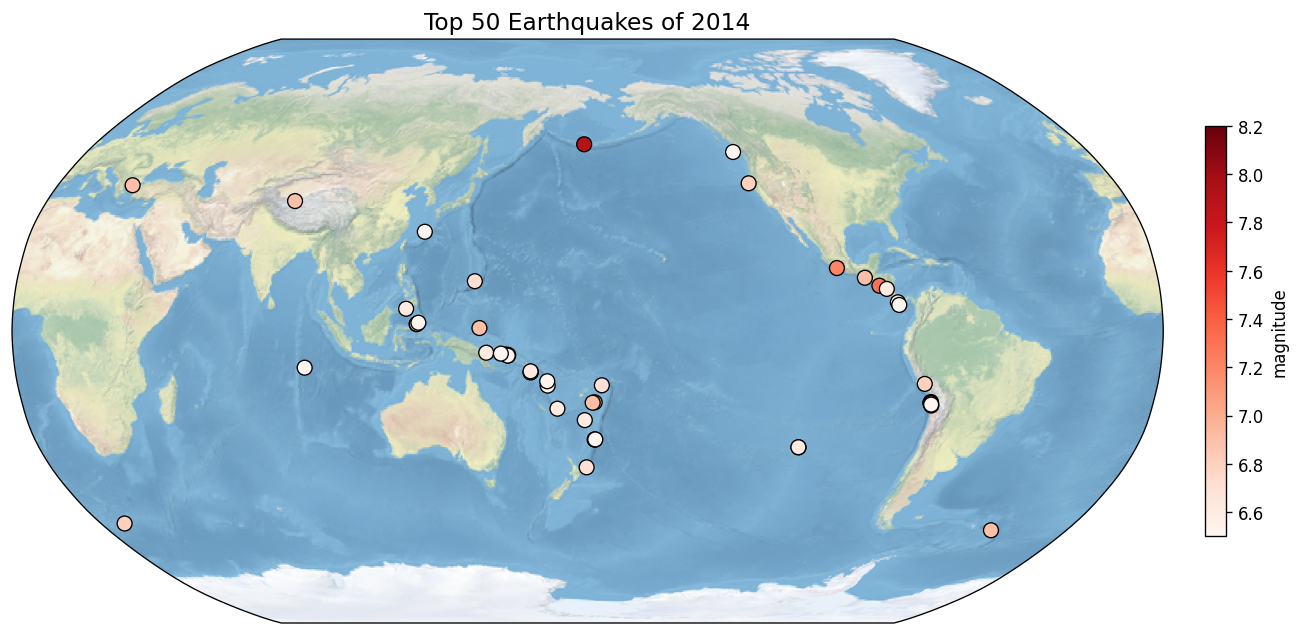

In [3]:
df["time"] = pd.to_datetime(df["time"])
df_2014 = df[df["time"].dt.year == 2014]
top50 = df_2014.sort_values("mag", ascending=False).head(50)

# 2.绘图
plt.figure(figsize=(12, 6), dpi=120)
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ax.stock_img()

scatter = ax.scatter(
    top50["longitude"], top50["latitude"],
    c=top50["mag"],
    cmap="Reds",
    s=80,
    edgecolor="black",
    linewidth=0.8,
    transform=ccrs.PlateCarree() 
)

cbar = plt.colorbar(scatter, shrink=0.6, pad=0.03)
cbar.set_label("magnitude")

plt.title("Top 50 Earthquakes of 2014", fontsize=14)

plt.tight_layout()
plt.show()

## 2. Explore a netCDF dataset

In [4]:
# 读取数据
ds = xr.open_mfdataset("./Data/FLDAS_NOAH01_CP_GL_M_001/*.nc", engine="netcdf4")
ds = ds.rename({"X": "lon", "Y": "lat"})
tair_mean = ds["Tair_f_tavg"].mean("time") - 273.15

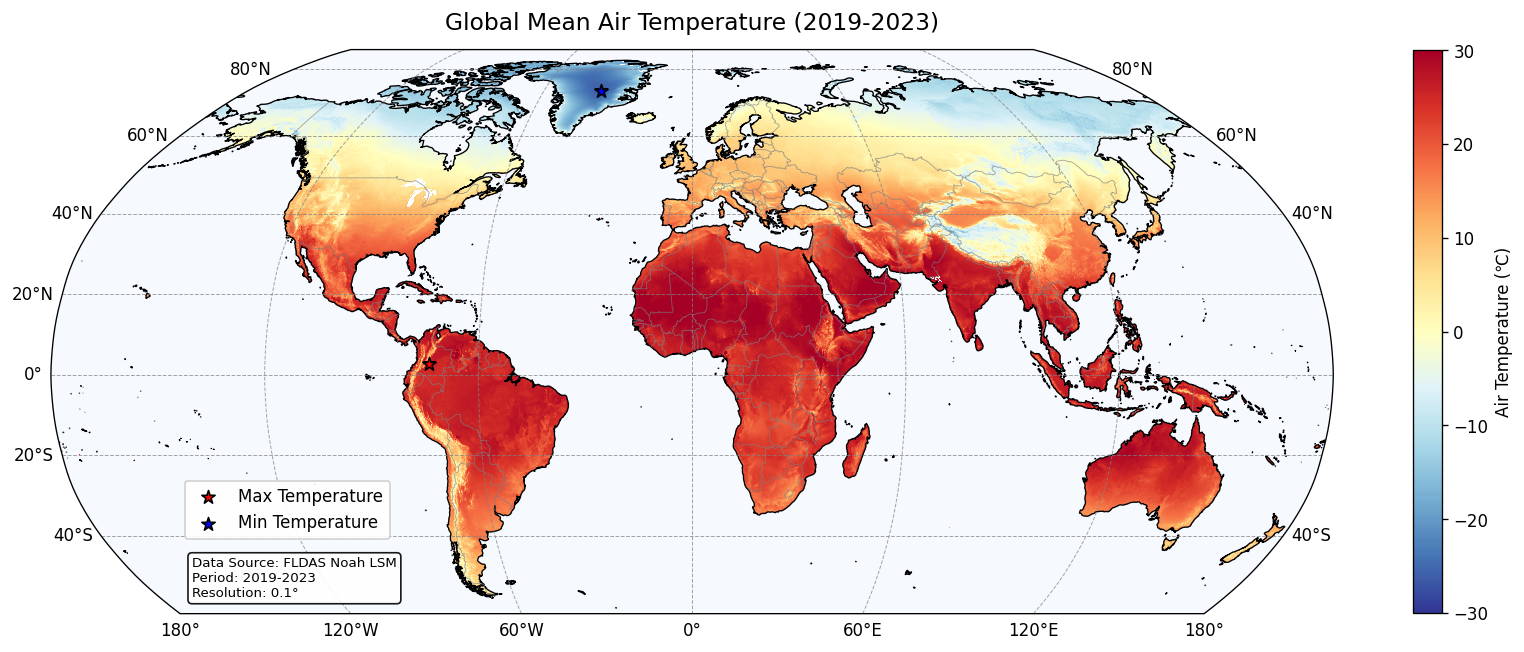

In [5]:
plt.figure(figsize=(14, 7), dpi=120)

# 1.投影：罗宾逊投影
proj_global = ccrs.Robinson(central_longitude=0)
ax = plt.axes(projection=proj_global)

# 2.地理要素
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), linewidth=0.8, edgecolor="black")
ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.5, edgecolor="gray", alpha=0.7)
ax.add_feature(cfeature.OCEAN, color="aliceblue", alpha=0.6)

tair_mean = tair_mean.compute()
im = tair_mean.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="RdYlBu_r",
    vmin=-30, vmax=30,
    add_colorbar=False
)

# 3.色标
cbar = plt.colorbar(im, shrink=0.7, pad=0.05)
cbar.set_label("Air Temperature (℃)", fontsize=10)

# 4.标题
plt.title("Global Mean Air Temperature (2019-2023)", fontsize=14, pad=12)

# 5.网格线
gl = ax.gridlines(draw_labels=True, linewidth=0.6, linestyle="--", alpha=0.7, color="gray")
gl.top_labels = False
gl.right_labels = False

# 6.X/Y轴标签与刻度
ax.set_xlabel("Longitude", fontsize=10, labelpad=10)
ax.set_ylabel("Latitude", fontsize=10, labelpad=10)

# 7.标注、图例
max_flat_idx = tair_mean.argmax().values
max_lat_idx, max_lon_idx = np.unravel_index(max_flat_idx, tair_mean.shape)
max_lon = tair_mean.lon.values[max_lon_idx]
max_lat = tair_mean.lat.values[max_lat_idx]

min_flat_idx = tair_mean.argmin().values
min_lat_idx, min_lon_idx = np.unravel_index(min_flat_idx, tair_mean.shape)
min_lon = tair_mean.lon.values[min_lon_idx]
min_lat = tair_mean.lat.values[min_lat_idx]

ax.scatter(max_lon, max_lat, c="red", s=70, marker="*", 
           edgecolor="black", transform=ccrs.PlateCarree(), label="Max Temperature")
ax.scatter(min_lon, min_lat, c="blue", s=70, marker="*", 
           edgecolor="black", transform=ccrs.PlateCarree(), label="Min Temperature")
ax.legend(
    loc="upper left",
    bbox_to_anchor=(0.098, 0.25),
    framealpha=0.9)

# 8.文本框
text_info = "Data Source: FLDAS Noah LSM\nPeriod: 2019-2023\nResolution: 0.1°"
ax.text(
    0.11, 0.03, text_info,
    transform=ax.transAxes,
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.9),
    fontsize=8
)

plt.tight_layout()
plt.show()

In [6]:
# 读取中国边界
china = gpd.read_file("Data/China_map.geojson")

china = china.to_crs("EPSG:4326")

china_whole = china.dissolve()
china_geom = china_whole.geometry.iloc[0]

lon_grid, lat_grid = np.meshgrid(tair_mean.lon.values, tair_mean.lat.values)

points = np.array([Point(lon, lat) for lon, lat in zip(lon_grid.ravel(), lat_grid.ravel())])
mask = np.array([p.within(china_geom) for p in points]).reshape(lon_grid.shape)

china_mask = xr.DataArray(
    mask,
    dims=["lat", "lon"],
    coords={"lat": tair_mean.lat, "lon": tair_mean.lon}
)

# 掩膜裁剪
tair_china = tair_mean.where(china_mask)

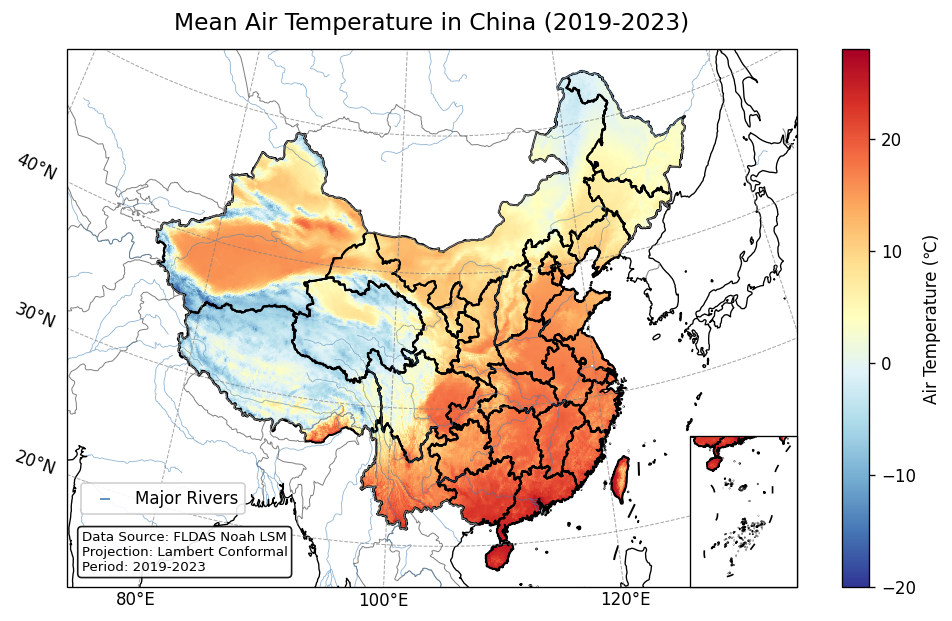

In [7]:
plt.figure(figsize=(10, 8), dpi=120)

# 1.投影：兰伯特等角圆锥投影
proj = ccrs.LambertConformal(central_longitude=105, central_latitude=35, standard_parallels=(25, 45))
ax = plt.axes(projection=proj)
ax.set_extent([73, 135, 17, 53], crs=ccrs.PlateCarree())

# 2.地理要素
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), linewidth=0.8, edgecolor="black")
ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.6, edgecolor="gray")
ax.add_feature(cfeature.RIVERS.with_scale("50m"), linewidth=0.5, edgecolor="steelblue", alpha=0.6)

im = tair_china.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="RdYlBu_r",
    vmin=-20, vmax=28,
    add_colorbar=False
)

china.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    facecolor="none",
    edgecolor="black",
    linewidth=1.2
)

# 3.色标
cbar = plt.colorbar(im, shrink=0.7, pad=0.05)
cbar.set_label("Air Temperature (℃)", fontsize=10)

# 4.标题
plt.title("Mean Air Temperature in China (2019-2023)", fontsize=14, pad=12)

# 5.网格线
gl = ax.gridlines(draw_labels=True,
                  linewidth=0.6,
                  linestyle="--",
                  alpha=0.7,
                  color="gray",
                  x_inline=False,
                  y_inline=False
)
gl.top_labels = False
gl.right_labels = False

# 6.坐标轴标签
gl.xpadding = 8
gl.ypadding = 8

gl.xlabel_style = {"size": 10, "rotation": 0, "ha": "center"}
gl.ylabel_style = {"size": 10}

# 8.图例
ax.scatter([], [], c="steelblue", linewidth=1, label="Major Rivers", marker="_")
ax.legend(loc="lower left",
          bbox_to_anchor=(0.008, 0.12),
          framealpha=0.9
)

# 9.文本框
text_info = "Data Source: FLDAS Noah LSM\nProjection: Lambert Conformal\nPeriod: 2019-2023"
ax.text(
    0.02, 0.03, text_info,
    transform=ax.transAxes,
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.9),
    fontsize=8
)

# 10.右下角南海诸岛插图
ax_inset = ax.inset_axes(
    [1 - 0.17, 0, 0.195, 0.28],
    projection=ccrs.PlateCarree()
)

ax_inset.set_extent([106, 123, 2, 23], crs=ccrs.PlateCarree())

tair_china.plot(
    ax=ax_inset,
    transform=ccrs.PlateCarree(),
    cmap="RdYlBu_r",
    vmin=-20,
    vmax=28,
    add_colorbar=False
)

china.plot(
    ax=ax_inset,
    transform=ccrs.PlateCarree(),
    facecolor="none",
    edgecolor="black",
    linewidth=1
)

ax_inset.gridlines(draw_labels=False, visible=False)
ax_inset.set_xticks([])
ax_inset.set_yticks([])
ax_inset.set_xlabel("")
ax_inset.set_ylabel("")

plt.subplots_adjust(left=0.16, right=0.92, top=0.92, bottom=0.12)
plt.show()